---
title: "Лекція 4. Структура мережі та динаміка процесів на ній"
description: "Математичне моделювання складних систем | PhD F3 «Комп'ютерні науки» | КрНУ ім. М. Остроградського"
author: "&copy; [Valeriy Sydorenko](https://www.linkedin.com/in/valeriy-sydorenko-6782279a/), 2026"
date: today
jupyter: python3
bibliography: mmss-references.bib

format:
  html:
    code-fold: show
    code-summary: "Показати код"
    code-overflow: wrap
    toc: true
    toc-depth: 4
    toc-location: right
    number-sections: false
    embed-resources: true
    smooth-scroll: true
---

::: callout-note
## Примітка
Лекція охоплює другу частину *Теми 5. Структура складних мереж (Structure of Complex Networks)* -- 1 год та першу частину *Теми 6. Динаміка процесів у складних мережах (Dynamics on Complex Networks)* -- 1 год. Тема 6 продовжиться в Лекції 5.

$$
\text{network structure}\rightarrow
\text{mesoscopic organization}\rightarrow
\text{network model class}\rightarrow
\text{state on network}\rightarrow
\text{dynamics on network}.
$$
:::

# Вступ
У Лекції 3 та ЛР3 ми перейшли до $G=(V,E)$ і розглянули adjacency matrix, degree, paths, clustering та centrality. Тепер завершуємо структурний опис: assortativity, communities/modularity, модельні класи мереж, multilayer і temporal networks.

Після цього поставимо нове питання:

> Якщо дві системи мають однакову кількість компонентів і однакові локальні правила поведінки, але різну topology, чи буде однаковою їхня макроскопічна динаміка?

Саме це переводить нас від *structure of networks* до *dynamics on networks* [@newman2018; @barabasi2016].

# Тема 5. Структура складних мереж (Structure of Complex Networks)

## 1. Від локальних характеристик до мезорівня
Корисно розрізняти:
$$
\text{micro}\rightarrow\text{meso}\rightarrow\text{macro}.
$$
- *мікрорівень (micro-level)* -- вузол і локальне оточення;
- *мезорівень (meso-level)* -- groups, communities, cores, motifs;
- *макрорівень (macro-level)* -- глобальна topology та статистичні властивості.

## 2. Асортативність (assortativity)
Degree assortativity відповідає на питання: чи схильні high-degree nodes з'єднуватися з high-degree nodes?

Концептуально коефіцієнт $r$ є кореляційною характеристикою degree на кінцях ребер [@newman2018]:
$$
-1\le r\le1.
$$
Умовно $r>0$ -- assortative mixing, $r<0$ -- disassortative mixing, $r\approx0$ -- відсутність вираженої лінійної degree-assortative pattern.

Але $r\approx0$ не означає відсутності іншої структури.

## 3. Атрибутивна асортативність
Нехай $c_i$ -- категоріальна ознака вузла. Можна досліджувати, чи переважають зв'язки $c_i=c_j$ над очікуваними за baseline.

$$
\text{degree assortativity}\neq\text{attribute assortativity}.
$$

## 4. Спільноти (communities)
Інтуїтивно community -- група вузлів із відносно щільними внутрішніми зв'язками. Але потрібен формальний criterion.

Нехай $c_i$ -- community label. Потрібно порівняти observed within-group connectivity з baseline. Звідси modularity [@newman2018].

## 5. Модульність (modularity)
Для undirected network:
$$
Q=
\frac{1}{2m}
\sum_{i,j}
\left(
a_{ij}-\frac{k_i k_j}{2m}
\right)
\delta(c_i,c_j).
$$
Тут $m=|E|$, а $\frac{k_i k_j}{2m}$ задає null expectation.

Отже,
$$
Q=Q(G,\mathcal{C},\text{null model}).
$$

## 6. Простий приклад modularity
Нехай два трикутники $\{1,2,3\}$ і $\{4,5,6\}$ сполучено ребром $(3,4)$:
$$
E=\{12,13,23,45,46,56,34\},\qquad m=7.
$$
Candidate partition:
$$
C_1=\{1,2,3\},\qquad C_2=\{4,5,6\}.
$$
Шість із семи ребер є внутрішніми, але modularity оцінює це не ізольовано, а відносно null expectation.

## 7. Community detection -- задача моделювання
$$
G\xrightarrow{\mathcal{A}}\mathcal{C}.
$$
Різні algorithms можуть повертати різні partitions через різні objectives, stochastic optimization, resolution effects, hierarchy або overlapping structure.

Тому коректніше говорити не «знайдено справжні communities», а «за обраним algorithm і criterion отримано partition з такими властивостями».

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import networkx as nx

G_comm = nx.Graph()
G_comm.add_edges_from([
    (1,2),(1,3),(2,3),
    (4,5),(4,6),(5,6),
    (3,4)
])
communities=[{1,2,3},{4,5,6}]
Q=nx.algorithms.community.modularity(G_comm,communities)
print("Кількість ребер:",G_comm.number_of_edges())
print("Modularity Q:",round(Q,4))

Кількість ребер: 7
Modularity Q: 0.3571


## 8. Візуальна очевидність не замінює критерію
Для маленького прикладу дві групи видно майже без обчислень.

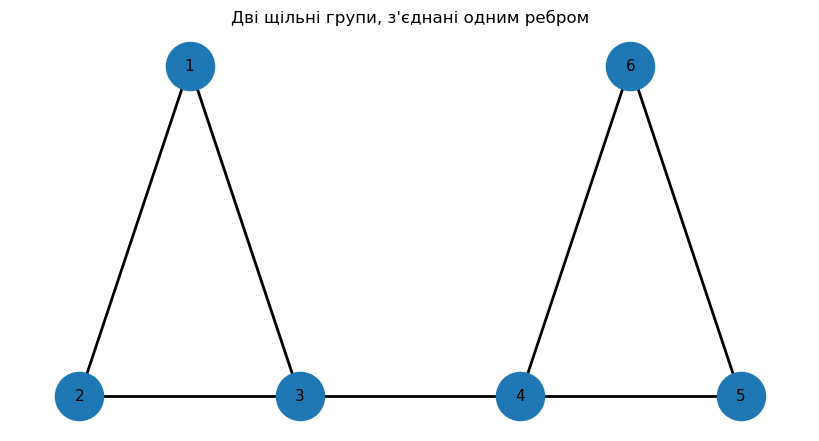

In [2]:
pos={1:(0,1),2:(-1,0),3:(1,0),4:(3,0),5:(5,0),6:(4,1)}
plt.figure(figsize=(8,4))
nx.draw(G_comm,pos,with_labels=True,node_size=1200,font_size=11,width=2)
plt.title("Дві щільні групи, з'єднані одним ребром")
plt.show()

Для великої мережі layout може створювати оманливі visual clusters:
$$
\text{visual cluster}\neq\text{validated community}.
$$
Так само високе $Q$ не є автоматичним доказом предметно значущих груп.

## 9. Моделі мереж як baseline
Модель мережі задає механізм або baseline:
$$
\text{observed network}\leftrightarrow\text{generative / null model}.
$$
Класичні орієнтири: random network, small-world network та мережі з неоднорідним degree distribution. Це не взаємовиключна універсальна таксономія реальних мереж [@newman2018; @barabasi2016].

## 10. Випадкова мережа (random network)
У Erdős--Rényi $G(n,p)$ кожна можлива пара з'єднується незалежно з probability $p$.
$$
\mathbb{E}[M]=p\binom{n}{2},
\qquad
\mathbb{E}[k]=p(n-1).
$$
Навіть коли реальний mechanism інший, random network корисна як null model.

## 11. Навіщо null model
Саме $C_{obs}=0.25$ малоінформативне. Якщо $C_{rand}\approx0.24$, ефект слабкий; якщо $C_{rand}\approx0.01$, інтерпретація інша.

Тому:
$$
\text{observed statistic}\quad\text{vs}\quad\text{baseline distribution}.
$$

## 12. Мережа малого світу (small-world network)
Ідея Watts--Strogatz поєднує високу локальну clustering і короткі глобальні paths. Модель стартує з regular ring і вводить rewiring probability $p$ [@newmanBarabasiWatts2006; @barabasi2016].

За $p=0$ -- regular structure; за малих $p$ кілька shortcut edges різко скорочують paths; за $p\rightarrow1$ структура стає значно більш random.

## 13. Scale-free як модельна ідеалізація
Класична гіпотеза:
$$
P(k)\propto k^{-\gamma}.
$$
Barabási--Albert демонструє growth + preferential attachment:
$$
P(i\text{ receives new edge})\propto k_i.
$$
[@barabasi2016]

::: callout-warning
## Застереження
Log--log plot, який «виглядає як пряма», не доводить power law:
$$
\text{heavy-tailed}\neq\text{power-law}\neq\text{scale-free mechanism}.
$$
:::

## 14. Порівняємо три topology
Створимо ER, WS і BA networks однакового $N$ і приблизно порівнянного mean degree. Мета -- побачити, що однаковий масштаб не означає однакову topology.

In [3]:
N=100
seed=42
G_er=nx.erdos_renyi_graph(N,0.06,seed=seed)
G_ws=nx.watts_strogatz_graph(N,6,0.08,seed=seed)
G_ba=nx.barabasi_albert_graph(N,3,seed=seed)

def network_summary(G):
    degrees=np.array([d for _,d in G.degree()])
    if nx.is_connected(G):
        L=nx.average_shortest_path_length(G)
    else:
        gcc=max(nx.connected_components(G),key=len)
        L=nx.average_shortest_path_length(G.subgraph(gcc))
    return {
        "N":G.number_of_nodes(),
        "M":G.number_of_edges(),
        "mean_degree":degrees.mean(),
        "degree_std":degrees.std(),
        "average_clustering":nx.average_clustering(G),
        "path_length_GCC":L
    }

summary=pd.DataFrame({
    "ER":network_summary(G_er),
    "WS":network_summary(G_ws),
    "BA":network_summary(G_ba)
}).T
summary.round(3)

,N,M,mean_degree,degree_std,average_clustering,path_length_GCC
ER,100.0,269.0,5.38,2.130,0.054,2.877
WS,100.0,300.0,6.00,0.632,0.465,3.656
BA,100.0,291.0,5.82,5.505,0.187,2.515


Особливо важливий не один показник, а structural profile:
$$
(\langle k\rangle,\sigma_k,C,L).
$$
Близький $\langle k\rangle$ не означає близьких $\sigma_k$, $C$ та $L$.

## 15. Багатошарові мережі (multilayer networks)
Для тих самих вузлів можуть існувати $E^{reply}$, $E^{mention}$, $E^{repost}$. Їх агрегація в $E^{all}$ втрачає тип взаємодії.

Multilayer representation:
$$
\mathcal{G}=\{G^{[1]},G^{[2]},\ldots,G^{[L]}\}.
$$
Це суттєво, якщо process поширюється різними layers за різними правилами.

## 16. Часові мережі (temporal networks)
У багатьох системах:
$$
G=G(t).
$$
Для поширення важлива не лише наявність edges, а й їх temporal order.

Якщо $A\rightarrow B$ відбувається в $t_1$, а $B\rightarrow C$ у $t_2>t_1$, це може утворити time-respecting path. У зворотному порядку -- ні.

## 17. Підсумок Теми 5
$$
\boxed{
\text{local}\rightarrow
\text{mesoscopic}\rightarrow
\text{global}\rightarrow
\text{multilayer/temporal}
}
$$
Назви «small-world» чи «scale-free» не повинні замінювати статистичне обґрунтування.

# Тема 6. Динаміка процесів у складних мережах (Dynamics on Complex Networks)

## 18. Structure та dynamics -- різні компоненти
$G=(V,E)$ задає потенційні interactions, але не behavior. Додаємо node state $x_i(t)$ і evolution rule:
$$
x_i(t+1)=
F_i\left(
x_i(t),
\{x_j(t):j\in\mathcal{N}_i\},
\theta
\right).
$$

## 19. Векторний запис
$$
\mathbf{x}(t)=[x_1(t),\ldots,x_N(t)]^T,
$$
$$
\mathbf{x}(t+1)=
\mathbf{F}(\mathbf{x}(t),A,\Theta).
$$
На відміну від aggregate $x(t+1)=f(x(t))$, topology тут входить у dynamic mechanism.

## 20. Локальний вплив сусідів
Нормований local mean:
$$
\bar x_{\mathcal{N}_i}(t)=
\frac{1}{k_i}\sum_j a_{ij}x_j(t).
$$
Наприклад:
$$
x_i(t+1)=
(1-\alpha)x_i(t)+
\alpha\bar x_{\mathcal{N}_i}(t).
$$
Той самий $\alpha$ може породжувати різні trajectories за різних $A$.

## 21. Graph Laplacian
$$
L=D-A,
$$
де $D=\operatorname{diag}(k_1,\ldots,k_N)$.

Базова diffusion model:
$$
\frac{d\mathbf{x}}{dt}=-\kappa L\mathbf{x}.
$$
Формально:
$$
\mathbf{x}(t)=e^{-\kappa Lt}\mathbf{x}(0).
$$
Спектральні властивості $L$ пов'язані з темпом network dynamics [@newman2018].

## 22. Ручний приклад: однакові states, різна topology
Нехай
$$
\mathbf{x}(0)=[1,0,0,0]^T.
$$
Порівнюємо path $1-2-3-4$ та star із центром 1.

У star усі peripheral nodes мають direct contact із source. У path вплив на node 4 проходить через intermediates.

$$
\text{same rule}+
\text{same initial state}+
\text{different topology}
\Rightarrow
\text{different transient dynamics}.
$$

## 23. SI-подібна модель
Нехай $x_i(t)\in\{0,1\}$. Якщо вузол має
$$
m_i(t)=\sum_j a_{ij}x_j(t)
$$
active neighbors, а кожний контакт передає state незалежно з probability $\beta$, то
$$
P(x_i(t+1)=1\mid x_i(t)=0)=
1-(1-\beta)^{m_i(t)}.
$$
Activated node залишається activated.

## 24. Чому саме $1-(1-\beta)^{m_i}$
Не отримати state від одного active neighbor: $1-\beta$.

Не отримати від $m_i$ independent active neighbors:
$$
(1-\beta)^{m_i}.
$$
Отже, хоча б одна successful transmission:
$$
1-(1-\beta)^{m_i}.
$$

## 25. Макроскопічна величина
$$
\rho(t)=\frac{1}{N}\sum_{i=1}^N x_i(t).
$$
Маємо:
$$
A\rightarrow\{x_i(t)\}\rightarrow\rho(t).
$$
Topology впливає на local transitions, а вони формують emergent macro-dynamics.

## 26. Обчислювальна реалізація

In [4]:
def simulate_si(G,beta=0.20,steps=25,initial_node=None,seed=42):
    rng=np.random.default_rng(seed)
    nodes=list(G.nodes())
    state={node:0 for node in nodes}
    if initial_node is None:
        initial_node=nodes[0]
    state[initial_node]=1
    prevalence=[sum(state.values())/len(nodes)]

    for _ in range(steps):
        new_state=state.copy()
        for node in nodes:
            if state[node]==1:
                continue
            active_neighbors=sum(state[nbr] for nbr in G.neighbors(node))
            p_activate=1-(1-beta)**active_neighbors
            if rng.random()<p_activate:
                new_state[node]=1
        state=new_state
        prevalence.append(sum(state.values())/len(nodes))
    return np.asarray(prevalence)

## 27. Одна realization ще не є topology comparison
Потрібен ensemble:
$$
\{\rho^{(r)}(t)\}_{r=1}^{R}.
$$
Для кожної topology фіксуємо однакові $N$, близький mean degree, однакові $\beta$, steps і number of realizations.

In [5]:
def simulate_ensemble(G,beta=0.20,steps=25,runs=200,initial_node=None):
    trajectories=[]
    for seed in range(runs):
        trajectories.append(
            simulate_si(G,beta,steps,initial_node,seed)
        )
    X=np.vstack(trajectories)
    return {
        "mean":X.mean(axis=0),
        "q05":np.quantile(X,0.05,axis=0),
        "q95":np.quantile(X,0.95,axis=0),
        "raw":X
    }

## 28. Контрольований topology experiment
Щоб initial condition не була випадковим confounder, у кожній мережі виберемо node з degree, найближчим до median degree.

In [6]:
def median_degree_node(G):
    degree=dict(G.degree())
    median_k=np.median(list(degree.values()))
    return min(degree,key=lambda node:abs(degree[node]-median_k))

initial_nodes={
    "ER":median_degree_node(G_er),
    "WS":median_degree_node(G_ws),
    "BA":median_degree_node(G_ba)
}
initial_nodes

{'ER': 4, 'WS': 0, 'BA': 11}

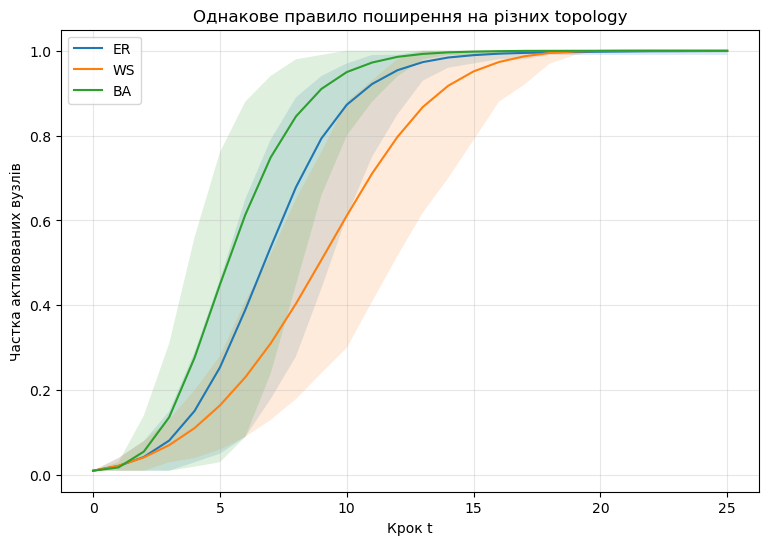

In [7]:
results={
 "ER":simulate_ensemble(G_er,0.20,25,200,initial_nodes["ER"]),
 "WS":simulate_ensemble(G_ws,0.20,25,200,initial_nodes["WS"]),
 "BA":simulate_ensemble(G_ba,0.20,25,200,initial_nodes["BA"])
}

t=np.arange(26)
plt.figure(figsize=(9,6))
for name,result in results.items():
    plt.plot(t,result["mean"],label=name)
    plt.fill_between(t,result["q05"],result["q95"],alpha=0.15)
plt.xlabel("Крок t")
plt.ylabel("Частка активованих вузлів")
plt.title("Однакове правило поширення на різних topology")
plt.legend()
plt.grid(alpha=0.3)
plt.show()

## 29. Як інтерпретувати експеримент
Process rule зафіксовано: $\beta=0.20$. Відмінності curves пов'язані з поєднанням degree heterogeneity, clustering, paths, initial node і stochastic realization.

Коректний висновок:

> За однакового локального правила та контрольованих параметрів різні network topologies можуть породжувати різну macro-dynamics.

Сильніший causal claim потребує окремого experimental design.

## 30. Structure--dynamics relation як дослідницька проблема
Нас цікавить:
$$
G\longmapsto\mathcal{D}(G),
$$
де $\mathcal{D}$ може бути time to 50% activation, final cascade size, synchronization time, extinction probability або resilience after perturbation.

RQ:
> *Які structural properties $G$ визначають або модифікують $\mathcal{D}(G)$?*

## 31. Structural metric не є автоматично dynamic predictor
High degree centrality не гарантує maximum spreading influence; high clustering не завжди прискорює diffusion; short average path не визначає cascade size.

$$
\text{dynamic outcome}=
f(\text{topology},\text{process rule},\text{parameters},\text{initial conditions}).
$$
[@newman2018; @newmanBarabasiWatts2006]

## 32. Що залишаємо для Лекції 5
Продовжимо Тему 6: diffusion, state spreading, cascades, threshold processes, synchronization, stability, robustness, resilience та систематичний вплив topology на macroscopic behavior.

Після цього відкриємо *Тему 7. Багаторівневі, багатомасштабні та гібридні моделі*:
$$
\text{network dynamics}\rightarrow
\text{multiple scales}\rightarrow
\text{hybrid representation}.
$$

# 33. Зв'язок із ЛР4
Нормативна назва: *«Лабораторна робота 4. Моделювання та дослідження динамічних процесів у складних мережах».*

ЛР3 дала *Network Model Specification v0.3*. ЛР4 додає:
$$
G+
\text{node states}+
\text{transition rule}+
\text{parameters}+
\text{initial conditions}.
$$
Артефакт:
$$
\text{Network Dynamics Specification v0.4}.
$$

# 34. Підсумкова концептуальна схема
```{mermaid}
%%{init: {'theme': 'base', 'themeVariables': {'fontSize':'18px','fontFamily':'Trebuchet MS, Verdana, Arial, sans-serif','primaryColor':'#E8F3FF','primaryBorderColor':'#3478A8','secondaryColor':'#FFF0C9','tertiaryColor':'#E7F6EC','lineColor':'#536878'}}}%%
flowchart LR
 G("Network<br/>G=(V,E)") --> S("Structural<br/>organization")
 S --> C("Communities /<br/>Assortativity")
 S --> T("Network<br/>model class")
 T --> X("Node states<br/>x_i(t)")
 C --> X
 X --> R("Local transition<br/>rule")
 R --> D("Dynamics<br/>on network")
 D --> M("Macroscopic<br/>behavior")
```

# Контрольні запитання
1. Чим micro-, meso- та macro-level structure відрізняються?
2. Що вимірює degree assortativity?
3. Чому $r\approx0$ не означає відсутність структури?
4. Чим attribute assortativity відрізняється від degree assortativity?
5. Що називають community?
6. Яку роль відіграє null model у modularity?
7. Що означає $k_i k_j/(2m)$?
8. Чому community detection не гарантує «істинних» communities?
9. Для чого random network models?
10. Які параметри задають $G(n,p)$?
11. Що означає small-world property?
12. Яку роль відіграють shortcut edges?
13. Що означає $P(k)\propto k^{-\gamma}$?
14. Чому log--log plot не доводить power law?
15. Що демонструє preferential attachment?
16. Навіщо multilayer network?
17. Чим temporal network відрізняється від static aggregate?
18. Що таке time-respecting path?
19. Чим structure відрізняється від dynamics on network?
20. Як adjacency matrix входить у dynamic model?
21. Що таке graph Laplacian?
22. Як topology впливає на diffusion?
23. Як виводиться $1-(1-\beta)^{m_i}$?
24. Що означає $\rho(t)$?
25. Чому однієї stochastic realization недостатньо?
26. Що контролювати у structure--dynamics experiment?
27. Чому centrality не є автоматичним predictor of spreading influence?
28. Які процеси розглянемо в продовженні Теми 6?

# Висновки
1. Network structure має micro-, meso- та macro-level organization.
2. Assortativity характеризує тенденцію зв'язків між вузлами з подібними властивостями, але не вичерпує структуру.
3. Community detection залежить від criterion, algorithm і null model.
4. Modularity порівнює observed within-group connectivity з baseline.
5. Random, small-world та scale-free models -- інструменти структурного мислення, а не готові ярлики.
6. Multilayer і temporal representations зберігають інформацію, яку втрачає static aggregation.
7. Topology сама не задає dynamics -- потрібні node states і transition rules.
8. У network dynamics adjacency matrix входить у закон еволюції.
9. Однакові local rules на різних topology можуть породжувати різну macro-dynamics.
10. Structure--dynamics relation потрібно досліджувати контрольованим computational experiment.
11. У Лекції 5 завершуємо Тему 6 та переходимо до multilevel/multiscale/hybrid models.

# Джерела та корисні ресурси
Використовується спільна накопичувальна база `mmss-references.bib`.

- [Network Science -- Albert-László Barabási](https://networksciencebook.com/)
- [NetworkX documentation](https://networkx.org/documentation/stable/)
- [NetworkX community algorithms](https://networkx.org/documentation/stable/reference/algorithms/community.html)
- [NetworkX graph generators](https://networkx.org/documentation/stable/reference/generators.html)
- [NumPy documentation](https://numpy.org/doc/stable/)
- [Matplotlib documentation](https://matplotlib.org/stable/)

# References